In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [ ]:
data = pd.read_csv("Mall_Customers.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [ ]:
data.head()
data.describe()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
data.isnull().sum()

,0
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [ ]:
data.shape

(200, 5)

In [ ]:
X = data[['Annual Income (k$)', 'Spending Score (1-100)']]
print("Features selected for clustering: Annual Income and Spending Score")

Features selected for clustering: Annual Income and Spending Score


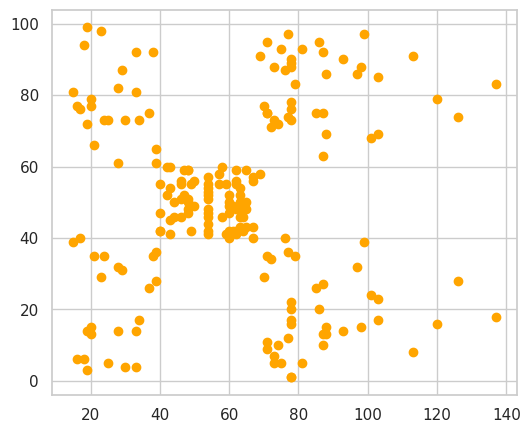

In [ ]:

plt.figure(figsize=(6,5))
plt.scatter(
X['Annual Income (k$)'],
X['Spending Score (1-100)'],color='orange'
)

In [ ]:
# Apply StandardScaler to normalize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature scaling complete using StandardScaler")

Feature scaling complete using StandardScaler


In [ ]:
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X_scaled)
print("Model trained successfully")

Model trained successfully


In [ ]:
labels = kmeans.labels_
data['Cluster'] = labels
data[['Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']].head()

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


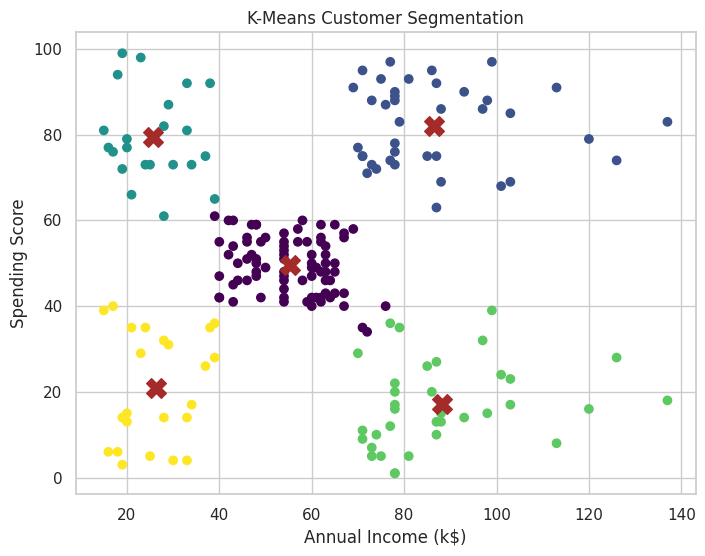

In [ ]:
# Visualize the clusters by plotting Annual Income against Spending Score, with co
plt.figure(figsize=(8,6))
plt.scatter(
X['Annual Income (k$)'],
X['Spending Score (1-100)'],
c=labels,
cmap='viridis'
)
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
centers[:,0],
centers[:,1],
c='brown',
s=200,
marker='X'
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("K-Means Customer Segmentation")
plt.show()

In [ ]:
# Calculate and display model evaluation metrics: Silhouette Score, WCSS (Inertia),
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)

wcss=kmeans.inertia_
print("WCSS:", wcss)

db_score = davies_bouldin_score(X_scaled, labels)
print("DB Index:", db_score)

Silhouette Score: 0.5546571631111091
WCSS: 65.56840815571681
DB Index: 0.5722356162263352
